In [1]:

from google.colab import files

uploaded = files.upload()


Saving order_history_kaggle_data.csv to order_history_kaggle_data.csv


In [2]:


import pandas as pd
import io

filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

display(df.head())



Dataset Shape: (21321, 29)

Column Names:
['Restaurant ID', 'Restaurant name', 'Subzone', 'City', 'Order ID', 'Order Placed At', 'Order Status', 'Delivery', 'Distance', 'Items in order', 'Instructions', 'Discount construct', 'Bill subtotal', 'Packaging charges', 'Restaurant discount (Promo)', 'Restaurant discount (Flat offs, Freebies & others)', 'Gold discount', 'Brand pack discount', 'Total', 'Rating', 'Review', 'Cancellation / Rejection reason', 'Restaurant compensation (Cancellation)', 'Restaurant penalty (Rejection)', 'KPT duration (minutes)', 'Rider wait time (minutes)', 'Order Ready Marked', 'Customer complaint tag', 'Customer ID']


,Restaurant ID,Restaurant name,Subzone,City,Order ID,Order Placed At,Order Status,Delivery,Distance,Items in order,...,Rating,Review,Cancellation / Rejection reason,Restaurant compensation (Cancellation),Restaurant penalty (Rejection),KPT duration (minutes),Rider wait time (minutes),Order Ready Marked,Customer complaint tag,Customer ID
0,20320607,Swaad,Sector 4,Delhi NCR,6168884918,"11:38 PM, September 10 2024",Delivered,Zomato Delivery,3km,"1 x Grilled Chicken Jamaican Tender, 1 x Grill...",...,NaN,NaN,NaN,NaN,NaN,18.35,11.6,Correctly,NaN,5d6c2b96db963098bc69768bea504c8bf46106a8a5178e...
1,20320607,Swaad,Sector 4,Delhi NCR,6170707559,"11:34 PM, September 10 2024",Delivered,Zomato Delivery,2km,"1 x Peri Peri Fries, 1 x Fried Chicken Angara ...",...,NaN,NaN,NaN,NaN,NaN,16.95,3.6,Correctly,NaN,0781815deb4a10a574e9fee4fa0b86b074d4a0b36175d5...
2,20320607,Swaad,Sector 4,Delhi NCR,6169375019,"03:52 PM, September 10 2024",Delivered,Zomato Delivery,<1km,1 x Bone in Peri Peri Grilled Chicken,...,NaN,NaN,NaN,NaN,NaN,14.05,12.2,Correctly,NaN,f93362f5ce5382657482d164e368186bcec9c6225fd93d...
3,20320607,Swaad,Sector 4,Delhi NCR,6151677434,"03:45 PM, September 10 2024",Delivered,Zomato Delivery,2km,"1 x Fried Chicken Ghostbuster Tender, 1 x Anga...",...,4.0,NaN,NaN,NaN,NaN,19.00,3.3,Correctly,NaN,1ed226d1b8a5f7acee12fc1d6676558330a3b2b742af5d...
4,20320607,Swaad,Sector 4,Delhi NCR,6167540897,"03:04 PM, September 10 2024",Delivered,Zomato Delivery,2km,"1 x Peri Peri Krispers, 1 x Fried Chicken Anga...",...,NaN,NaN,NaN,NaN,NaN,15.97,1.0,Correctly,NaN,d21a2ac6ea06b31cc3288ab20c4ef2f292066c096f2c5f...


In [3]:

!pip install pyspark -q


In [4]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *

# Initialize Spark
spark = SparkSession.builder \
    .appName("FoodX_Big_Data_Analytics") \
    .config("spark.driver.memory", "4g") \
    .getOrCreate()

print("Apache Spark Version:", spark.version)
print("Spark Session Created Successfully!")


Apache Spark Version: 4.0.5
Spark Session Created Successfully!


In [6]:

from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

# Save uploaded CSV
with open("/content/food_delivery.csv", "wb") as f:
    f.write(uploaded[filename])

print("Dataset uploaded:", filename)


Saving order_history_kaggle_data.csv to order_history_kaggle_data (1).csv
Dataset uploaded: order_history_kaggle_data (1).csv


In [7]:

df = spark.read \
    .option("header", True) \
    .option("inferSchema", True) \
    .option("multiLine", True) \
    .option("escape", '"') \
    .csv("/content/food_delivery.csv")

print("Total Records:", df.count())
print("Total Columns:", len(df.columns))

df.show(5, truncate=False)


Total Records: 21321
Total Columns: 29
+-------------+---------------+--------+---------+----------+---------------------------+------------+---------------+--------+---------------------------------------------------------------------------------------+------------+------------------+-------------+-----------------+---------------------------+--------------------------------------------------+-------------+-------------------+------+------+------+-------------------------------+--------------------------------------+------------------------------+----------------------+-------------------------+------------------+----------------------+----------------------------------------------------------------+
|Restaurant ID|Restaurant name|Subzone |City     |Order ID  |Order Placed At            |Order Status|Delivery       |Distance|Items in order                                                                         |Instructions|Discount construct|Bill subtotal|Packaging charges|Restaurant

In [8]:

# Display column names and data types
df.printSchema()

# Check missing values
missing_values = df.select([
    count(when(col(c).isNull(), c)).alias(c)
    for c in df.columns
])

missing_values.show(truncate=False)


root
 |-- Restaurant ID: integer (nullable = true)
 |-- Restaurant name: string (nullable = true)
 |-- Subzone: string (nullable = true)
 |-- City: string (nullable = true)
 |-- Order ID: long (nullable = true)
 |-- Order Placed At: string (nullable = true)
 |-- Order Status: string (nullable = true)
 |-- Delivery: string (nullable = true)
 |-- Distance: string (nullable = true)
 |-- Items in order: string (nullable = true)
 |-- Instructions: string (nullable = true)
 |-- Discount construct: string (nullable = true)
 |-- Bill subtotal: double (nullable = true)
 |-- Packaging charges: double (nullable = true)
 |-- Restaurant discount (Promo): double (nullable = true)
 |-- Restaurant discount (Flat offs, Freebies & others): double (nullable = true)
 |-- Gold discount: double (nullable = true)
 |-- Brand pack discount: double (nullable = true)
 |-- Total: double (nullable = true)
 |-- Rating: double (nullable = true)
 |-- Review: string (nullable = true)
 |-- Cancellation / Rejection reas

In [9]:

# Duplicate records
print("Duplicate Records:",
      df.count() - df.dropDuplicates().count())

# Unique customers
print("Unique Customers:",
      df.select("Customer ID").distinct().count())

# Unique restaurants
print("Unique Restaurants:",
      df.select("Restaurant ID").distinct().count())

# Order status distribution
df.groupBy("Order Status") \
  .count() \
  .orderBy(desc("count")) \
  .show()

# Dataset summary
df.describe().show()


Duplicate Records: 0
Unique Customers: 11607
Unique Restaurants: 21
+----------------+-----+
|    Order Status|count|
+----------------+-----+
|       Delivered|21131|
|        Rejected|  158|
|        Returned|   25|
|Return cancelled|    3|
|       Picked up|    3|
|       Timed out|    1|
+----------------+-----+

+-------+-------------------+--------------------+-----------------+---------+--------------------+--------------------+------------+---------------+--------+--------------------+--------------------+------------------+------------------+------------------+---------------------------+--------------------------------------------------+-------------------+-------------------+-----------------+------------------+--------------------+-------------------------------+--------------------------------------+------------------------------+----------------------+-------------------------+------------------+----------------------+--------------------+
|summary|      Restaurant ID|   

In [10]:

# Duplicate records
print("Duplicate Records:",
      df.count() - df.dropDuplicates().count())

# Unique customers
print("Unique Customers:",
      df.select("Customer ID").distinct().count())

# Unique restaurants
print("Unique Restaurants:",
      df.select("Restaurant ID").distinct().count())

# Order status distribution
df.groupBy("Order Status") \
  .count() \
  .orderBy(desc("count")) \
  .show()

# Dataset summary
df.describe().show()


Duplicate Records: 0
Unique Customers: 11607
Unique Restaurants: 21
+----------------+-----+
|    Order Status|count|
+----------------+-----+
|       Delivered|21131|
|        Rejected|  158|
|        Returned|   25|
|Return cancelled|    3|
|       Picked up|    3|
|       Timed out|    1|
+----------------+-----+

+-------+-------------------+--------------------+-----------------+---------+--------------------+--------------------+------------+---------------+--------+--------------------+--------------------+------------------+------------------+------------------+---------------------------+--------------------------------------------------+-------------------+-------------------+-----------------+------------------+--------------------+-------------------------------+--------------------------------------+------------------------------+----------------------+-------------------------+------------------+----------------------+--------------------+
|summary|      Restaurant ID|   

In [11]:

from pyspark.sql.functions import col, sum, when

missing_values = df.select([
    sum(when(col(c).isNull(), 1).otherwise(0)).alias(c)
    for c in df.columns
])

missing_values.show(truncate=False)


+-------------+---------------+-------+----+--------+---------------+------------+--------+--------+--------------+------------+------------------+-------------+-----------------+---------------------------+--------------------------------------------------+-------------+-------------------+-----+------+------+-------------------------------+--------------------------------------+------------------------------+----------------------+-------------------------+------------------+----------------------+-----------+
|Restaurant ID|Restaurant name|Subzone|City|Order ID|Order Placed At|Order Status|Delivery|Distance|Items in order|Instructions|Discount construct|Bill subtotal|Packaging charges|Restaurant discount (Promo)|Restaurant discount (Flat offs, Freebies & others)|Gold discount|Brand pack discount|Total|Rating|Review|Cancellation / Rejection reason|Restaurant compensation (Cancellation)|Restaurant penalty (Rejection)|KPT duration (minutes)|Rider wait time (minutes)|Order Ready Marked|

In [12]:

from pyspark.sql.functions import *
from pyspark.sql.types import *

# Create a working DataFrame
food_df = df

# Remove exact duplicate records
food_df = food_df.dropDuplicates()

# Convert order timestamp into proper datetime
food_df = food_df.withColumn(
    "Order Timestamp",
    to_timestamp(
        col("Order Placed At"),
        "hh:mm a, MMMM d yyyy"
    )
)

# Extract useful time features
food_df = food_df.withColumn(
    "Order Date", to_date(col("Order Timestamp"))
).withColumn(
    "Order Hour", hour(col("Order Timestamp"))
).withColumn(
    "Order Day", date_format(col("Order Timestamp"), "EEEE")
).withColumn(
    "Order Month", month(col("Order Timestamp"))
)

# Convert delivery distance into numeric kilometres
food_df = food_df.withColumn(
    "Distance KM",
    regexp_extract(col("Distance"), r"[\d.]+", 0).cast("double")
)

# Verify transformations
food_df.select(
    "Order Placed At",
    "Order Timestamp",
    "Order Hour",
    "Order Day",
    "Distance",
    "Distance KM"
).show(10, truncate=False)


+---------------------------+-------------------+----------+---------+--------+-----------+
|Order Placed At            |Order Timestamp    |Order Hour|Order Day|Distance|Distance KM|
+---------------------------+-------------------+----------+---------+--------+-----------+
|09:27 PM, September 05 2024|2024-09-05 21:27:00|21        |Thursday |1km     |1.0        |
|08:16 PM, September 04 2024|2024-09-04 20:16:00|20        |Wednesday|1km     |1.0        |
|07:45 PM, September 05 2024|2024-09-05 19:45:00|19        |Thursday |3km     |3.0        |
|11:57 PM, September 01 2024|2024-09-01 23:57:00|23        |Sunday   |2km     |2.0        |
|08:26 PM, September 07 2024|2024-09-07 20:26:00|20        |Saturday |1km     |1.0        |
|12:58 PM, September 06 2024|2024-09-06 12:58:00|12        |Friday   |7km     |7.0        |
|05:13 PM, September 06 2024|2024-09-06 17:13:00|17        |Friday   |<1km    |1.0        |
|07:27 PM, September 11 2024|2024-09-11 19:27:00|19        |Wednesday|11km    |1

In [13]:

print("Original Records:", df.count())
print("Processed Records:", food_df.count())

print(
    "Successfully Parsed Timestamps:",
    food_df.filter(col("Order Timestamp").isNotNull()).count()
)

print(
    "Missing Timestamps:",
    food_df.filter(col("Order Timestamp").isNull()).count()
)

print(
    "Missing Customer IDs:",
    food_df.filter(col("Customer ID").isNull()).count()
)


Original Records: 21321
Processed Records: 21321
Successfully Parsed Timestamps: 21321
Missing Timestamps: 0
Missing Customer IDs: 0


In [14]:

from pyspark.sql.functions import *

food_df = food_df.withColumn(
    "Distance KM",
    when(
        lower(trim(col("Distance"))) == "<1km",
        0.5
    ).otherwise(
        regexp_extract(col("Distance"), r"[\d.]+", 0).cast("double")
    )
)

food_df.select("Distance", "Distance KM").distinct().show(20)


+--------+-----------+
|Distance|Distance KM|
+--------+-----------+
|     2km|        2.0|
|     9km|        9.0|
|     1km|        1.0|
|    <1km|        0.5|
|    18km|       18.0|
|     8km|        8.0|
|    20km|       20.0|
|    15km|       15.0|
|    12km|       12.0|
|     3km|        3.0|
|    11km|       11.0|
|     7km|        7.0|
|     5km|        5.0|
|    21km|       21.0|
|    13km|       13.0|
|    10km|       10.0|
|    16km|       16.0|
|     6km|        6.0|
|    14km|       14.0|
|    17km|       17.0|
+--------+-----------+
only showing top 20 rows


In [15]:

food_df.createOrReplaceTempView("food_orders")

print("Food delivery SQL table created successfully!")


Food delivery SQL table created successfully!


In [16]:

restaurant_analysis = spark.sql("""
SELECT
    `Restaurant name`,
    COUNT(`Order ID`) AS total_orders,
    ROUND(AVG(Total), 2) AS average_order_value,
    ROUND(AVG(Rating), 2) AS average_rating,
    SUM(CASE WHEN `Order Status` = 'Delivered'
        THEN 1 ELSE 0 END) AS delivered_orders
FROM food_orders
GROUP BY `Restaurant name`
ORDER BY total_orders DESC
""")

restaurant_analysis.show(21, truncate=False)


+--------------------+------------+-------------------+--------------+----------------+
|Restaurant name     |total_orders|average_order_value|average_rating|delivered_orders|
+--------------------+------------+-------------------+--------------+----------------+
|Aura Pizzas         |14548       |739.04             |4.32          |14417           |
|Swaad               |6332        |559.94             |4.43          |6282            |
|Dilli Burger Adda   |227         |448.06             |4.18          |223             |
|Tandoori Junction   |154         |867.96             |4.65          |151             |
|The Chicken Junction|32          |386.91             |4.69          |32              |
|Masala Junction     |28          |327.22             |4.83          |26              |
+--------------------+------------+-------------------+--------------+----------------+



In [17]:

hourly_demand = spark.sql("""
SELECT
    `Order Hour`,
    COUNT(`Order ID`) AS total_orders
FROM food_orders
GROUP BY `Order Hour`
ORDER BY total_orders DESC
""")

hourly_demand.show(24)


+----------+------------+
|Order Hour|total_orders|
+----------+------------+
|        20|        2912|
|        19|        2419|
|        21|        2296|
|        22|        1748|
|        18|        1611|
|        23|        1477|
|        13|        1142|
|        17|        1069|
|        14|        1032|
|         0|         957|
|        12|         909|
|        16|         905|
|         1|         833|
|        15|         824|
|         2|         488|
|         3|         389|
|        11|         305|
|         4|           5|
+----------+------------+



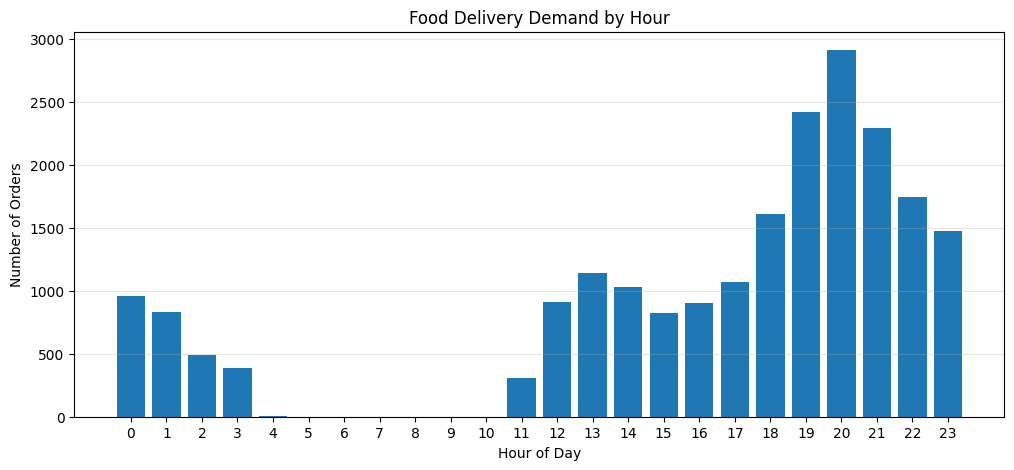

In [18]:

hour_data = hourly_demand.toPandas()

plt.figure(figsize=(12,5))
plt.bar(hour_data["Order Hour"], hour_data["total_orders"])

plt.title("Food Delivery Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Orders")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.show()


In [19]:

daily_demand = spark.sql("""
SELECT
    `Order Day`,
    COUNT(`Order ID`) AS total_orders
FROM food_orders
GROUP BY `Order Day`
ORDER BY total_orders DESC
""")

daily_demand.show()


+---------+------------+
|Order Day|total_orders|
+---------+------------+
| Saturday|        3923|
|   Friday|        3403|
|Wednesday|        3077|
|   Sunday|        2958|
|  Tuesday|        2885|
| Thursday|        2879|
|   Monday|        2196|
+---------+------------+



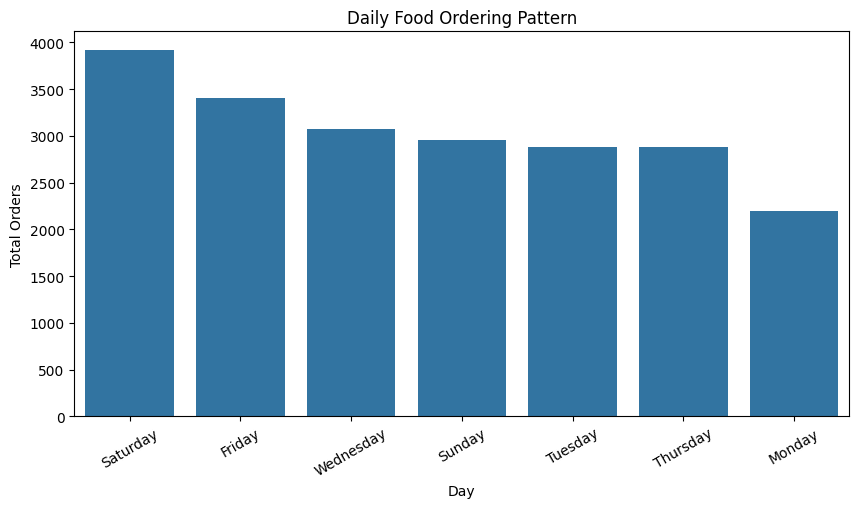

In [20]:

daily_data = daily_demand.toPandas()

plt.figure(figsize=(10,5))
sns.barplot(
    data=daily_data,
    x="Order Day",
    y="total_orders"
)

plt.title("Daily Food Ordering Pattern")
plt.xlabel("Day")
plt.ylabel("Total Orders")
plt.xticks(rotation=30)
plt.show()


In [21]:

customer_analysis = spark.sql("""
SELECT
    `Customer ID`,
    COUNT(`Order ID`) AS total_orders,
    ROUND(SUM(Total), 2) AS total_spending,
    ROUND(AVG(Total), 2) AS average_spending
FROM food_orders
WHERE `Order Status` = 'Delivered'
GROUP BY `Customer ID`
ORDER BY total_spending DESC
""")

customer_analysis.show(10, truncate=False)


+----------------------------------------------------------------+------------+--------------+----------------+
|Customer ID                                                     |total_orders|total_spending|average_spending|
+----------------------------------------------------------------+------------+--------------+----------------+
|c521ccf21e7bb2207c3f08d578b6e028d2c3b25986cb35dd5930ede1d8a643da|60          |27767.93      |462.8           |
|8b5c4d6170343fbee92a6e577268b8aa8492105bdacbb8c6d9c2855f9bad8a4f|23          |25207.83      |1095.99         |
|12b07b9c3370baa5dd15fbfbc43c3dbc379fe66f73dbda9526c651d3fe501507|29          |22416.31      |772.98          |
|4f0c8bb49d63ece05f5a6e04183b590b0add9efc83dbd4179e2960d917920216|28          |21355.94      |762.71          |
|b64eade2d814bda0a3b16234e44400a4a9c0c44e5d6738a42e9e3c62b3d25723|38          |20185.62      |531.2           |
|87914cdf29e9abadd81682bc1f10c5060e5ef20a11a3afa9ecf8b6f48d4fe98c|20          |19210.95      |960.55    

In [22]:

delivery_analysis = spark.sql("""
SELECT
    `Restaurant name`,
    ROUND(AVG(`KPT duration (minutes)`), 2) AS avg_kpt,
    ROUND(AVG(`Rider wait time (minutes)`), 2) AS avg_rider_wait,
    ROUND(AVG(`Distance KM`), 2) AS avg_distance
FROM food_orders
WHERE `Order Status` = 'Delivered'
GROUP BY `Restaurant name`
ORDER BY avg_kpt DESC
""")

delivery_analysis.show(21, truncate=False)


+--------------------+-------+--------------+------------+
|Restaurant name     |avg_kpt|avg_rider_wait|avg_distance|
+--------------------+-------+--------------+------------+
|Tandoori Junction   |21.13  |6.08          |5.65        |
|Dilli Burger Adda   |19.41  |5.09          |3.12        |
|Swaad               |17.78  |4.51          |3.73        |
|Aura Pizzas         |17.09  |4.94          |4.33        |
|The Chicken Junction|15.55  |7.26          |9.06        |
|Masala Junction     |13.7   |4.57          |9.73        |
+--------------------+-------+--------------+------------+



In [23]:

cancellation_analysis = spark.sql("""
SELECT
    `Order Status`,
    `Cancellation / Rejection reason`,
    COUNT(*) AS total_orders
FROM food_orders
WHERE `Order Status` != 'Delivered'
GROUP BY
    `Order Status`,
    `Cancellation / Rejection reason`
ORDER BY total_orders DESC
""")

cancellation_analysis.show(30, truncate=False)


+----------------+-------------------------------+------------+
|Order Status    |Cancellation / Rejection reason|total_orders|
+----------------+-------------------------------+------------+
|Rejected        |Cancelled by Customer          |86          |
|Rejected        |Cancelled by Zomato            |56          |
|Returned        |Cancelled by Zomato            |22          |
|Rejected        |Merchant device issue          |12          |
|Returned        |Cancelled by Customer          |3           |
|Return cancelled|Cancelled by Zomato            |3           |
|Rejected        |Kitchen is full                |3           |
|Picked up       |NULL                           |3           |
|Rejected        |Items out of stock             |1           |
|Timed out       |NULL                           |1           |
+----------------+-------------------------------+------------+



In [24]:

revenue_analysis = spark.sql("""
SELECT
    COUNT(*) AS total_orders,
    ROUND(SUM(
        CASE WHEN `Order Status` = 'Delivered'
        THEN Total ELSE 0 END
    ), 2) AS delivered_order_value,

    ROUND(AVG(
        CASE WHEN `Order Status` = 'Delivered'
        THEN Total END
    ), 2) AS average_delivered_order_value,

    ROUND(AVG(`Bill subtotal`), 2) AS average_bill_subtotal,

    ROUND(AVG(`Restaurant discount (Promo)`), 2)
    AS average_promo_discount

FROM food_orders
""")

revenue_analysis.show(truncate=False)


+------------+---------------------+-----------------------------+---------------------+----------------------+
|total_orders|delivered_order_value|average_delivered_order_value|average_bill_subtotal|average_promo_discount|
+------------+---------------------+-----------------------------+---------------------+----------------------+
|21321       |1.442337976E7        |682.57                       |750.08               |65.09                 |
+------------+---------------------+-----------------------------+---------------------+----------------------+



In [25]:

from pyspark.sql.functions import *

customer_features = food_df.filter(
    col("Order Status") == "Delivered"
).groupBy("Customer ID").agg(

    count("Order ID").alias("total_orders"),

    round(sum(col("Total").cast("double")), 2)
    .alias("total_spending"),

    round(avg(col("Total").cast("double")), 2)
    .alias("average_order_value"),

    round(
        avg(
            coalesce(col("Restaurant discount (Promo)").cast("double"), lit(0.0)) +
            coalesce(col("Restaurant discount (Flat offs, Freebies & others)").cast("double"), lit(0.0)) +
            coalesce(col("Gold discount").cast("double"), lit(0.0)) +
            coalesce(col("Brand pack discount").cast("double"), lit(0.0))
        ), 2
    ).alias("average_discount")

)

customer_features.show(10, truncate=False)

print("Total customer profiles:", customer_features.count())


+----------------------------------------------------------------+------------+--------------+-------------------+----------------+
|Customer ID                                                     |total_orders|total_spending|average_order_value|average_discount|
+----------------------------------------------------------------+------------+--------------+-------------------+----------------+
|42f5963a62e83f9f4f69a645bf8aaaf4f39f643ea5c4e5bde90840137740c9b1|4           |1199.63       |299.91             |170.63          |
|fa2c4e247a890cf3f4e54db4de1c1437cdfeb296eb074a392a42ac4d77a170c3|1           |628.95        |628.95             |0.0             |
|9bdf70778be6b7129d375172dce13afe735217fa3b970a701a4e4b81426d0abf|2           |522.38        |261.19             |74.75           |
|989e6ec3b20e11e8e9c5406afde95ee642764254cc2cc788b123bf373746c26a|1           |793.8         |793.8              |0.0             |
|2851008a6acfa992af0ab5c3a208d053b23c9e07f82b787a1792d9435ce34bf3|2         

In [26]:

from pyspark.ml.feature import VectorAssembler, StandardScaler

assembler = VectorAssembler(
    inputCols=[
        "total_orders",
        "total_spending",
        "average_order_value",
        "average_discount"
    ],
    outputCol="raw_features",
    handleInvalid="skip"
)

assembled_data = assembler.transform(customer_features)

scaler = StandardScaler(
    inputCol="raw_features",
    outputCol="scaled_features",
    withMean=True,
    withStd=True
)

scaler_model = scaler.fit(assembled_data)

scaled_data = scaler_model.transform(assembled_data)

scaled_data.select(
    "Customer ID",
    "scaled_features"
).show(5, truncate=False)


+----------------------------------------------------------------+-----------------------------------------------------------------------------------+
|Customer ID                                                     |scaled_features                                                                    |
+----------------------------------------------------------------+-----------------------------------------------------------------------------------+
|42f5963a62e83f9f4f69a645bf8aaaf4f39f643ea5c4e5bde90840137740c9b1|[1.0782700005665968,-0.03296177436561567,-0.8525528327110482,0.5317486635170173]   |
|fa2c4e247a890cf3f4e54db4de1c1437cdfeb296eb074a392a42ac4d77a170c3|[-0.41264306860280026,-0.4115343123201469,-0.14393037364074043,-0.7774501972775547]|
|9bdf70778be6b7129d375172dce13afe735217fa3b970a701a4e4b81426d0abf|[0.08432795445366542,-0.48222975524755707,-0.9359404500682155,-0.20391321758820197]|
|989e6ec3b20e11e8e9c5406afde95ee642764254cc2cc788b123bf373746c26a|[-0.41264306860280026,-0.302

In [28]:

import builtins

best_k = builtins.max(scores, key=lambda x: x[1])[0]

print("Best number of clusters:", best_k)



Best number of clusters: 2


In [30]:

kmeans = KMeans(
    k=best_k,
    seed=42,
    featuresCol="scaled_features",
    predictionCol="Customer Segment"
)

kmeans_model = kmeans.fit(scaled_data)

segmented_customers = kmeans_model.transform(scaled_data)

segmented_customers.select(
    "Customer ID",
    "total_orders",
    "total_spending",
    "average_order_value",
    "Customer Segment"
).show(20, truncate=False)


+----------------------------------------------------------------+------------+--------------+-------------------+----------------+
|Customer ID                                                     |total_orders|total_spending|average_order_value|Customer Segment|
+----------------------------------------------------------------+------------+--------------+-------------------+----------------+
|42f5963a62e83f9f4f69a645bf8aaaf4f39f643ea5c4e5bde90840137740c9b1|4           |1199.63       |299.91             |0               |
|fa2c4e247a890cf3f4e54db4de1c1437cdfeb296eb074a392a42ac4d77a170c3|1           |628.95        |628.95             |0               |
|9bdf70778be6b7129d375172dce13afe735217fa3b970a701a4e4b81426d0abf|2           |522.38        |261.19             |0               |
|989e6ec3b20e11e8e9c5406afde95ee642764254cc2cc788b123bf373746c26a|1           |793.8         |793.8              |0               |
|2851008a6acfa992af0ab5c3a208d053b23c9e07f82b787a1792d9435ce34bf3|2         

In [31]:

segment_summary = segmented_customers.groupBy(
    "Customer Segment"
).agg(

    count("*").alias("customer_count"),

    round(avg("total_orders"), 2).alias("avg_orders"),

    round(avg("total_spending"), 2).alias("avg_spending"),

    round(avg("average_order_value"), 2).alias("avg_order_value"),

    round(avg("average_discount"), 2).alias("avg_discount")

).orderBy("Customer Segment")

segment_summary.show(truncate=False)


+----------------+--------------+----------+------------+---------------+------------+
|Customer Segment|customer_count|avg_orders|avg_spending|avg_order_value|avg_discount|
+----------------+--------------+----------+------------+---------------+------------+
|0               |10530         |1.42      |904.0       |656.81         |97.66       |
|1               |1015          |6.04      |4831.78     |1100.08        |139.33      |
+----------------+--------------+----------+------------+---------------+------------+



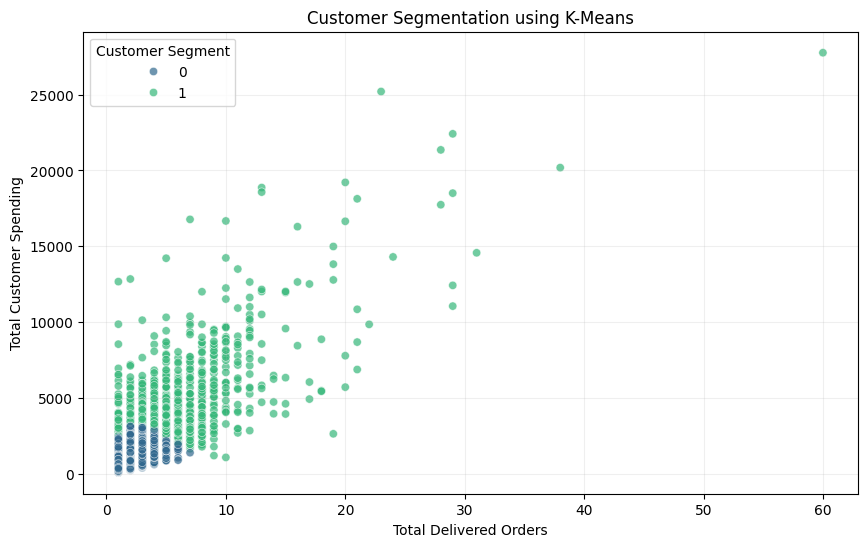

In [32]:

segment_pd = segmented_customers.select(
    "total_orders",
    "total_spending",
    "Customer Segment"
).toPandas()

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=segment_pd,
    x="total_orders",
    y="total_spending",
    hue="Customer Segment",
    palette="viridis",
    alpha=0.7
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Total Delivered Orders")
plt.ylabel("Total Customer Spending")
plt.legend(title="Customer Segment")
plt.grid(alpha=0.2)
plt.show()


In [33]:

from pyspark.ml.feature import StringIndexer

# Use delivered orders only
interactions = food_df.filter(
    (col("Order Status") == "Delivered") &
    col("Customer ID").isNotNull() &
    col("Restaurant ID").isNotNull()
)

# Count how frequently each customer orders from each restaurant
interactions = interactions.groupBy(
    "Customer ID", "Restaurant ID"
).agg(
    count("Order ID").alias("order_frequency")
)

# Convert customer and restaurant IDs into numeric indexes
customer_indexer = StringIndexer(
    inputCol="Customer ID",
    outputCol="user_idx"
)

restaurant_indexer = StringIndexer(
    inputCol="Restaurant ID",
    outputCol="restaurant_idx"
)

customer_indexer_model = customer_indexer.fit(interactions)
restaurant_indexer_model = restaurant_indexer.fit(interactions)

indexed_data = customer_indexer_model.transform(interactions)
indexed_data = restaurant_indexer_model.transform(indexed_data)

indexed_data = indexed_data.withColumn(
    "user_idx", col("user_idx").cast("int")
).withColumn(
    "restaurant_idx", col("restaurant_idx").cast("int")
)

indexed_data.show(10, truncate=False)


+----------------------------------------------------------------+-------------+---------------+--------+--------------+
|Customer ID                                                     |Restaurant ID|order_frequency|user_idx|restaurant_idx|
+----------------------------------------------------------------+-------------+---------------+--------+--------------+
|ce77b3d458a357c5621b2207321b09a79706959d7fb40bbbd34163ddb0209a97|20635699     |1              |9445    |1             |
|5ba75d89a8f39771af51e2b5ec82f2c7451728d4aad58caeb0eb674b84e72a21|20554001     |5              |4684    |3             |
|e44b1dc25dd51d0e1d183c8db91ec3beb3925d5b0db3bed86b669a016be69779|20635699     |4              |10436   |1             |
|cc69f5f3ac0c65f27bfc5cde1f625434e052331a81e28c82a43356c82363199a|20882713     |3              |9352    |7             |
|eb82233e570837f5deefba145104d1ac88aaebd9345cc306eec1b60a0afcf9d5|20554001     |2              |10729   |3             |
|f925750425ca950046ccb0d017d2381

In [34]:

train_data, test_data = indexed_data.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training Records:", train_data.count())
print("Testing Records:", test_data.count())


Training Records: 9982
Testing Records: 2428


In [35]:

from pyspark.ml.recommendation import ALS

als = ALS(
    userCol="user_idx",
    itemCol="restaurant_idx",
    ratingCol="order_frequency",
    rank=10,
    maxIter=10,
    regParam=0.1,
    implicitPrefs=True,
    alpha=1.0,
    coldStartStrategy="drop",
    seed=42
)

als_model = als.fit(train_data)

print("ALS Recommendation Model Trained Successfully!")


ALS Recommendation Model Trained Successfully!


In [38]:

from pyspark.sql.functions import (
    countDistinct,
    count,
    col,
    desc
)


In [39]:

active_customer = interactions.groupBy(
    "Customer ID"
).agg(
    countDistinct("Restaurant ID").alias("restaurants_tried"),
    count("*").alias("total_interactions")
).filter(
    col("restaurants_tried") >= 2
).orderBy(
    desc("total_interactions")
).limit(1)

active_customer.show(truncate=False)


+----------------------------------------------------------------+-----------------+------------------+
|Customer ID                                                     |restaurants_tried|total_interactions|
+----------------------------------------------------------------+-----------------+------------------+
|bde2288e31dda2c9c3726cea55a7a1850a91c9b87061c3508c0ea0dcdd141421|4                |4                 |
+----------------------------------------------------------------+-----------------+------------------+



In [40]:

# Convert selected customer into indexed format
selected_user = customer_indexer_model.transform(
    active_customer.select("Customer ID")
)

# Generate recommendations across all 21 restaurants
recommendations = als_model.recommendForUserSubset(
    selected_user.select("user_idx"),
    21
)

recommendations.show(truncate=False)


+--------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|user_idx|recommendations                                                                                                                                                                                                                                                                                                                                                                                             |
+--------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [41]:

from pyspark.sql.functions import explode

# Convert recommendation arrays into individual rows
recommended_restaurants = recommendations.select(
    "user_idx",
    explode("recommendations").alias("recommendation")
).select(
    "user_idx",
    col("recommendation.restaurant_idx").alias("restaurant_idx"),
    col("recommendation.rating").alias("predicted_preference")
)

# Create restaurant ID mapping
restaurant_mapping = spark.createDataFrame(
    [(i, str(name)) for i, name in
     enumerate(restaurant_indexer_model.labels)],
    ["restaurant_idx", "Restaurant ID"]
)

# Join restaurant IDs
recommended_restaurants = recommended_restaurants.join(
    restaurant_mapping,
    on="restaurant_idx",
    how="inner"
)

# Attach restaurant names and performance
restaurant_details = food_df.groupBy(
    "Restaurant ID", "Restaurant name"
).agg(
    count("Order ID").alias("total_orders"),
    round(avg("Rating"), 2).alias("average_rating")
)

recommended_restaurants = recommended_restaurants.join(
    restaurant_details,
    on="Restaurant ID",
    how="left"
)

recommended_restaurants.show(20, truncate=False)


+-------------+--------------+--------+--------------------+--------------------+------------+--------------+
|Restaurant ID|restaurant_idx|user_idx|predicted_preference|Restaurant name     |total_orders|average_rating|
+-------------+--------------+--------+--------------------+--------------------+------------+--------------+
|20659868     |0             |7       |0.00278081          |Aura Pizzas         |4614        |4.33          |
|20635699     |1             |7       |2.949983E-4         |Aura Pizzas         |4418        |4.34          |
|20882652     |2             |7       |1.4446676E-4        |Aura Pizzas         |2545        |4.33          |
|20554001     |3             |7       |0.0012177825        |Swaad               |2781        |4.45          |
|21077127     |4             |7       |0.023094658         |Aura Pizzas         |2051        |4.2           |
|20320607     |5             |7       |0.0032473207        |Swaad               |1774        |4.38          |
|21173951 

In [42]:

# Get selected customer's previously ordered restaurants
previously_ordered = interactions.join(
    active_customer.select("Customer ID"),
    on="Customer ID",
    how="inner"

).select("Restaurant ID").distinct()

# Exclude restaurants already ordered
final_recommendations = recommended_restaurants.join(
    previously_ordered,
    on="Restaurant ID",
    how="left_anti"
).orderBy(
    desc("predicted_preference")
)

print("PERSONALIZED RESTAURANT RECOMMENDATIONS")

final_recommendations.select(
    "Restaurant name",
    "predicted_preference",
    "average_rating",
    "total_orders"
).show(5, truncate=False)


PERSONALIZED RESTAURANT RECOMMENDATIONS
+-----------------+--------------------+--------------+------------+
|Restaurant name  |predicted_preference|average_rating|total_orders|
+-----------------+--------------------+--------------+------------+
|Tandoori Junction|0.31839544          |4.5           |72          |
|Dilli Burger Adda|0.06658122          |4.0           |34          |
|Aura Pizzas      |0.023094658         |4.2           |2051        |
|Tandoori Junction|0.010782195         |4.67          |16          |
|Swaad            |0.0032473207        |4.38          |1774        |
+-----------------+--------------------+--------------+------------+
only showing top 5 rows


In [43]:

# Convert selected customer into indexed format
selected_user = customer_indexer_model.transform(
    active_customer.select("Customer ID")
)

# Generate recommendations
recommendations = als_model.recommendForUserSubset(
    selected_user.select("user_idx"),
    21
)

recommendations.show(truncate=False)


+--------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|user_idx|recommendations                                                                                                                                                                                                                                                                                                                                                                                             |
+--------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [44]:

from pyspark.sql.functions import explode, col, desc

# Extract individual recommendations
recommended_restaurants = recommendations.select(
    "user_idx",
    explode("recommendations").alias("recommendation")
).select(
    "user_idx",
    col("recommendation.restaurant_idx").alias("restaurant_idx"),
    col("recommendation.rating").alias("predicted_preference")
)

# Create restaurant ID mapping
restaurant_mapping = spark.createDataFrame(
    [
        (i, int(restaurant_id))
        for i, restaurant_id in enumerate(
            restaurant_indexer_model.labels
        )
    ],
    ["restaurant_idx", "Restaurant ID"]
)

# Join restaurant IDs
recommended_restaurants = recommended_restaurants.join(
    restaurant_mapping,
    "restaurant_idx",
    "inner"
)

# Restaurant performance details
restaurant_details = food_df.groupBy(
    "Restaurant ID", "Restaurant name"
).agg(
    count("Order ID").alias("total_orders"),
    round(avg("Rating"), 2).alias("average_rating")
)

recommended_restaurants = recommended_restaurants.join(
    restaurant_details,
    "Restaurant ID",
    "left"
)

recommended_restaurants.show(20, truncate=False)


+-------------+--------------+--------+--------------------+--------------------+------------+--------------+
|Restaurant ID|restaurant_idx|user_idx|predicted_preference|Restaurant name     |total_orders|average_rating|
+-------------+--------------+--------+--------------------+--------------------+------------+--------------+
|20659868     |0             |7       |0.00278081          |Aura Pizzas         |4614        |4.33          |
|20882713     |7             |7       |-0.0046993196       |Swaad               |1079        |4.54          |
|21173951     |6             |7       |-0.002212748        |Aura Pizzas         |920         |4.35          |
|20968206     |9             |7       |-0.43955564         |Dilli Burger Adda   |109         |4.12          |
|20320607     |5             |7       |0.0032473207        |Swaad               |1774        |4.38          |
|20635699     |1             |7       |2.949983E-4         |Aura Pizzas         |4418        |4.34          |
|20554001 

In [45]:

previously_ordered = interactions.join(
    active_customer.select("Customer ID"),
    "Customer ID",
    "inner"
).select("Restaurant ID").distinct()

final_recommendations = recommended_restaurants.join(
    previously_ordered,
    "Restaurant ID",
    "left_anti"
).orderBy(
    desc("predicted_preference")
)

print("TOP 5 PERSONALIZED RESTAURANT RECOMMENDATIONS")

final_recommendations.select(
    "Restaurant name",
    "predicted_preference",
    "average_rating",
    "total_orders"
).show(5, truncate=False)


TOP 5 PERSONALIZED RESTAURANT RECOMMENDATIONS
+-----------------+--------------------+--------------+------------+
|Restaurant name  |predicted_preference|average_rating|total_orders|
+-----------------+--------------------+--------------+------------+
|Tandoori Junction|0.31839544          |4.5           |72          |
|Dilli Burger Adda|0.06658122          |4.0           |34          |
|Aura Pizzas      |0.023094658         |4.2           |2051        |
|Tandoori Junction|0.010782195         |4.67          |16          |
|Swaad            |0.0032473207        |4.38          |1774        |
+-----------------+--------------------+--------------+------------+
only showing top 5 rows


In [46]:

!pip install streamlit plotly -q


In [47]:

# Save analytical tables
restaurant_analysis.toPandas().to_csv(
    "/content/restaurant_analysis.csv", index=False
)

hourly_demand.toPandas().to_csv(
    "/content/hourly_demand.csv", index=False
)

daily_demand.toPandas().to_csv(
    "/content/daily_demand.csv", index=False
)

segment_summary.toPandas().to_csv(
    "/content/customer_segments.csv", index=False
)

delivery_analysis.toPandas().to_csv(
    "/content/delivery_analysis.csv", index=False
)

final_recommendations.toPandas().to_csv(
    "/content/recommendations.csv", index=False
)

print("All analytical results exported successfully!")


All analytical results exported successfully!


In [48]:

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, HTML

# Convert Spark analytical results into Pandas
restaurant_pd = restaurant_analysis.toPandas()
hourly_pd = hourly_demand.toPandas()
daily_pd = daily_demand.toPandas()
segment_pd = segment_summary.toPandas()
delivery_pd = delivery_analysis.toPandas()
recommendations_pd = final_recommendations.toPandas()

# Calculate dashboard KPIs
total_orders = food_df.count()

total_customers = food_df.select(
    "Customer ID"
).distinct().count()

total_restaurants = food_df.select(
    "Restaurant ID"
).distinct().count()

delivered_orders = food_df.filter(
    food_df["Order Status"] == "Delivered"
).count()

print("Dashboard data prepared successfully!")


Dashboard data prepared successfully!


In [49]:

display(HTML("""
<div style="background:#14213d;padding:25px;border-radius:12px;color:white">
    <h1 style="margin:0;color:white">FOODX</h1>
    <h3 style="margin:5px 0;color:#60a5fa">
        Big Data Analytics & Intelligent Recommendation System
    </h3>
    <p style="margin:0;color:#cbd5e1">
        Food Delivery | Customer Intelligence | Restaurant Analytics
    </p>
</div>
"""))

fig = go.Figure()

kpis = [
    ("TOTAL ORDERS", total_orders),
    ("CUSTOMERS", total_customers),
    ("RESTAURANTS", total_restaurants),
    ("DELIVERED ORDERS", delivered_orders)
]

fig = go.Figure()

for i, (label, value) in enumerate(kpis):
    fig.add_trace(go.Indicator(
        mode="number",
        value=value,
        title={"text": label},
        domain={"row": 0, "column": i}
    ))

fig.update_layout(
    grid={"rows": 1, "columns": 4, "pattern": "independent"},
    height=160,
    template="plotly_dark",
    paper_bgcolor="#14213d",
    font_color="white"
)

fig.show()


In [50]:

top_restaurants = restaurant_pd.sort_values(
    "total_orders", ascending=False
).head(10)

fig = px.bar(
    top_restaurants,
    x="Restaurant name",
    y="total_orders",
    color="average_rating",
    title="Top 10 Restaurants by Order Volume",
    template="plotly_dark",
    color_continuous_scale="Blues"
)

fig.update_layout(
    xaxis_title="Restaurant",
    yaxis_title="Total Orders",
    xaxis_tickangle=-35
)

fig.show()


In [51]:

fig = px.line(
    hourly_pd.sort_values("Order Hour"),
    x="Order Hour",
    y="total_orders",
    markers=True,
    title="Food Delivery Demand by Hour",
    template="plotly_dark"
)

fig.update_traces(line_width=3, marker_size=8)

fig.update_layout(
    xaxis_title="Hour of Day",
    yaxis_title="Number of Orders"
)

fig.show()


In [52]:

fig = px.pie(
    segment_pd,
    names="Customer Segment",
    values="customer_count",
    title="Customer Segmentation Distribution",
    hole=0.45,
    template="plotly_dark"
)

fig.show()


In [53]:

fig = px.bar(
    delivery_pd,
    x="Restaurant name",
    y=["avg_kpt", "avg_rider_wait"],
    barmode="group",
    title="Restaurant Delivery Operations Analysis",
    template="plotly_dark",
    labels={
        "value": "Minutes",
        "variable": "Performance Metric"
    }
)

fig.update_layout(xaxis_tickangle=-35)
fig.show()



In [54]:

display(HTML("""
<h2 style="color:#60a5fa">Personalized Restaurant Recommendations</h2>
<p>Recommendations generated using the ALS collaborative filtering model.</p>
"""))

display(
    recommendations_pd[
        ["Restaurant name",
         "predicted_preference",
         "average_rating",
         "total_orders"]
    ].head(5)
)


,Restaurant name,predicted_preference,average_rating,total_orders
0,Tandoori Junction,0.318395,4.50,72
1,Dilli Burger Adda,0.066581,4.00,34
2,Aura Pizzas,0.023095,4.20,2051
3,Tandoori Junction,0.010782,4.67,16
4,Swaad,0.003247,4.38,1774


In [55]:

print("=" * 55)
print("          FOODX PROJECT VALIDATION")
print("=" * 55)

print("\n1. DATASET")
print("Total Records:", food_df.count())
print("Total Columns:", len(food_df.columns))

print("\n2. CUSTOMER ANALYTICS")
print("Unique Customers:",
      food_df.select("Customer ID").distinct().count())

print("\n3. RESTAURANT ANALYTICS")
print("Unique Restaurants:",
      food_df.select("Restaurant ID").distinct().count())

print("\n4. CUSTOMER SEGMENTATION")
print("Number of Clusters:", best_k)
print("Segmented Customers:", segmented_customers.count())

print("\n5. RECOMMENDATION SYSTEM")
print("ALS Model:", "Successfully Trained")
print("Recommendations Generated:",
      final_recommendations.count())

print("\n6. ANALYTICS")
print("Restaurant Analysis:", restaurant_analysis.count())
print("Hourly Demand Analysis:", hourly_demand.count())
print("Daily Demand Analysis:", daily_demand.count())
print("Delivery Analysis:", delivery_analysis.count())

print("\n" + "=" * 55)
print("          FOODX VALIDATION COMPLETED")
print("=" * 55)


          FOODX PROJECT VALIDATION

1. DATASET
Total Records: 21321
Total Columns: 35

2. CUSTOMER ANALYTICS
Unique Customers: 11607

3. RESTAURANT ANALYTICS
Unique Restaurants: 21

4. CUSTOMER SEGMENTATION
Number of Clusters: 2
Segmented Customers: 11545

5. RECOMMENDATION SYSTEM
ALS Model: Successfully Trained
Recommendations Generated: 17

6. ANALYTICS
Restaurant Analysis: 6
Hourly Demand Analysis: 18
Daily Demand Analysis: 7
Delivery Analysis: 6

          FOODX VALIDATION COMPLETED


In [56]:

# Save final project outputs
import os

output_dir = "/content/FoodX_Results"
os.makedirs(output_dir, exist_ok=True)

restaurant_pd.to_csv(
    f"{output_dir}/restaurant_analysis.csv", index=False
)

hourly_pd.to_csv(
    f"{output_dir}/hourly_demand.csv", index=False
)

daily_pd.to_csv(
    f"{output_dir}/daily_demand.csv", index=False
)

segment_pd.to_csv(
    f"{output_dir}/customer_segments.csv", index=False
)

delivery_pd.to_csv(
    f"{output_dir}/delivery_analysis.csv", index=False
)

recommendations_pd.to_csv(
    f"{output_dir}/recommendations.csv", index=False
)

print("All FoodX results saved successfully!")


All FoodX results saved successfully!


In [58]:

import shutil
from google.colab import files

shutil.make_archive(
    "/content/FoodX_Project_Results",
    "zip",
    output_dir
)

files.download("/content/FoodX_Project_Results.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>